In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

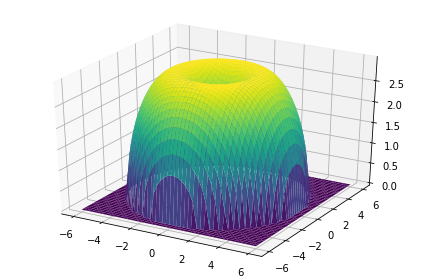

In [6]:
x, y = sp.symbols('x y')
R = 3
r = 2.5
f = sp.sqrt(R**2 - (sp.sqrt(x**2 + y**2) - r)**2)

display_rad = 6
display_shift = 0
x_display = (x, -display_rad + display_shift, display_rad + display_shift)
y_display = (y, -display_rad + display_shift, display_rad + display_shift)

sp.plotting.plot3d(f, x_display, y_display)

In [7]:
H = sp.hessian(f, (x, y))
print(H)

Matrix([[-0.333333333333333*x**2/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*(x**2 + y**2)) + 0.833333333333333*x**2*(0.4*sqrt(x**2 + y**2) - 1)/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*(x**2 + y**2)**(3/2)) - 0.231481481481482*x**2*(0.4*sqrt(x**2 + y**2) - 1)**2/((1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)**(3/2)*(x**2 + y**2)) - 0.833333333333333*(0.4*sqrt(x**2 + y**2) - 1)/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*sqrt(x**2 + y**2)), -0.333333333333333*x*y/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*(x**2 + y**2)) + 0.833333333333333*x*y*(0.4*sqrt(x**2 + y**2) - 1)/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*(x**2 + y**2)**(3/2)) - 0.231481481481482*x*y*(0.4*sqrt(x**2 + y**2) - 1)**2/((1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)**(3/2)*(x**2 + y**2))], [-0.333333333333333*x*y/(sqrt(1 - 0.694444444444444*(0.4*sqrt(x**2 + y**2) - 1)**2)*(x**2 + y**2)) + 0.833333333333333*x*y*(0.4*

In [8]:
# Obtain the eigenvalues of the 2x2 hessian
eigs = H.eigenvals(multiple=True)
lamda_1 = eigs[0]
lamda_2 = eigs[1]
print(lamda_1)
print(lamda_2)

-sqrt((288*(-4*x**2 - 4*y**2 + 20*sqrt(x**2 + y**2) + 11)**3*(256*x**10 + 1280*x**8*y**2 - 5120*x**8*sqrt(x**2 + y**2) + 35584*x**8 + 2560*x**6*y**4 - 20480*x**6*y**2*sqrt(x**2 + y**2) + 142336*x**6*y**2 - 85760*x**6*sqrt(x**2 + y**2) - 39584*x**6 + 2560*x**4*y**6 - 30720*x**4*y**4*sqrt(x**2 + y**2) + 213504*x**4*y**4 - 257280*x**4*y**2*sqrt(x**2 + y**2) - 118752*x**4*y**2 + 235840*x**4*sqrt(x**2 + y**2) + 269104*x**4 + 1280*x**2*y**8 - 20480*x**2*y**6*sqrt(x**2 + y**2) + 142336*x**2*y**6 - 257280*x**2*y**4*sqrt(x**2 + y**2) - 118752*x**2*y**4 + 471680*x**2*y**2*sqrt(x**2 + y**2) + 538208*x**2*y**2 + 106480*x**2*sqrt(x**2 + y**2) + 14641*x**2 + 256*y**10 - 5120*y**8*sqrt(x**2 + y**2) + 35584*y**8 - 85760*y**6*sqrt(x**2 + y**2) - 39584*y**6 + 235840*y**4*sqrt(x**2 + y**2) + 269104*y**4 + 106480*y**2*sqrt(x**2 + y**2) + 14641*y**2)*(2048*x**12 + 12288*x**10*y**2 - 56320*x**10*sqrt(x**2 + y**2) + 611840*x**10 + 30720*x**8*y**4 - 281600*x**8*y**2*sqrt(x**2 + y**2) + 3059200*x**8*y**2 - 320

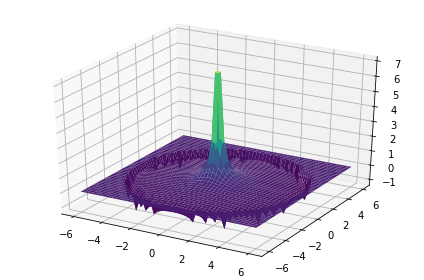

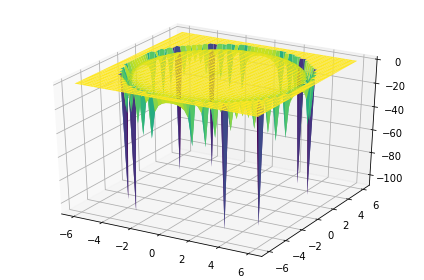

In [9]:
sp.plotting.plot3d(lamda_1, x_display, y_display)
sp.plotting.plot3d(lamda_2, x_display, y_display)

In [10]:
# Symbolically find max(lamda_i, 0) and max(-lamda_i, 0)
# algorithm: add original function to absolute value, then divide by 2
a = sp.symbols('a')
g = lambda a: sp.simplify((a + sp.Abs(a)) / 2)
h = lambda a: sp.simplify(((- a) + sp.Abs(- a)) / 2)

lamda_1_plus = g(lamda_1)
lamda_2_plus = g(lamda_2)

lamda_1_minus = h(lamda_1)
lamda_2_minus = h(lamda_2)

# sp.plotting.plot3d(lamda_1_plus, x_display, y_display)
# sp.plotting.plot3d(lamda_2_plus, x_display, y_display)
# sp.plotting.plot3d(lamda_1_minus, x_display, y_display)
# sp.plotting.plot3d(lamda_2_minus,, x_display, y_display)

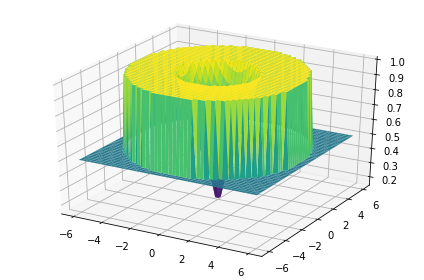

In [11]:
# The index of lack of convexity (normalized)
loc = (lamda_1_minus + lamda_2_minus) / (sp.Abs(lamda_1) + sp.Abs(lamda_2))
sp.plotting.plot3d(loc, x_display, y_display)


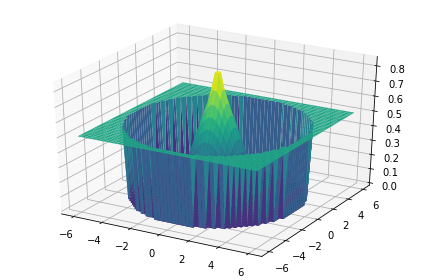

In [12]:
# index of convexity (normalized)
conv = (lamda_1_plus + lamda_2_plus) / (sp.Abs(lamda_1) + sp.Abs(lamda_2))
sp.plotting.plot3d(conv, x_display, y_display)

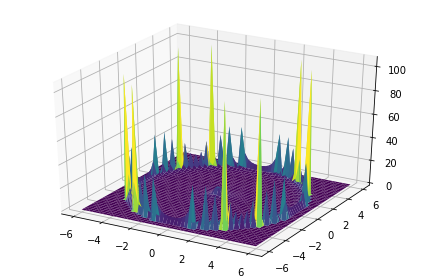

In [13]:
# places where there is only one eigenvalue
sp.plotting.plot3d(lamda_1 - lamda_2, x_display, y_display)